In [ ]:
# Import Library
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances
)

from google.colab import drive
drive.mount('/content/drive')

# Set Library
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = "/content/drive/MyDrive/ml-semester5/KUIS-1/outputKmeans"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("[INFO] Library berhasil diinstall.")
print(f"[INFO] Folder output: '{OUTPUT_DIR}' | Random state: {RANDOM_STATE}")

Mounted at /content/drive
[INFO] Library berhasil diinstall.
[INFO] Folder output: '/content/drive/MyDrive/ml-sem5/kuis1/outputKmeans' | Random state: 42


In [ ]:
# Load Dataset
df_raw = pd.read_csv('/content/drive/MyDrive/ml-sem5/kuis1/dataset/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
print(f"Data awal: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
df_raw.head()

Data awal: 70692 baris x 22 kolom


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [ ]:
# Cek data awal
print("Tipe data tiap kolom:")
print(df_raw.dtypes.value_counts())

print("\nTotal missing value per kolom (hanya yang > 0):")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value")

print(f"\nJumlah baris duplikat: {df_raw.duplicated().sum()}")

print("\nSebaran kelas Diabetes_binary (0=tidak, 1=diabetes):")
print(df_raw['Diabetes_binary'].value_counts().sort_index())

Tipe data tiap kolom:
float64    22
Name: count, dtype: int64

Total missing value per kolom (hanya yang > 0):
Tidak ada missing value

Jumlah baris duplikat: 1635

Sebaran kelas Diabetes_binary (0=tidak, 1=diabetes):
Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64


In [ ]:
# preprocessing
LABEL = 'Diabetes_binary'          # label sudah 0 dan 1
FITUR_DIBUANG = ['Income','CholCheck', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'Education']         # tambahkan fitur lain yang kamu buang sampai tersisa 15 fitur

df = df_raw.copy()
print(f"Data awal: {len(df)} baris x {df.shape[1]} kolom")
print(f"Sebaran kelas awal: {df[LABEL].value_counts().sort_index().to_dict()}")

df = df.drop(columns=FITUR_DIBUANG)
print(f"Setelah buang fitur       : {df.shape[1]} kolom (termasuk label)")

n_sebelum_dup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Setelah hapus duplikat    : {len(df)} baris (terbuang {n_sebelum_dup - len(df)})")
print(f"Sebaran kelas akhir       : {df[LABEL].value_counts().sort_index().to_dict()}")

y_label = df[LABEL].copy()   # label hanya untuk pembanding, tidak dipakai klastering
df_features = df.drop(columns=[LABEL]).astype(float)
print(f"Jumlah fitur untuk klastering: {df_features.shape[1]}")
print(f"Daftar fitur: {list(df_features.columns)}")

scaler = StandardScaler()
X_all = scaler.fit_transform(df_features.values)
X_scaled = X_all
print(f"Bentuk data siap klaster: {X_all.shape}")
print(f"Cek mean 0 dan std 1: {X_all.mean():.4f} / {X_all.std():.4f}")

Data awal: 70692 baris x 22 kolom
Sebaran kelas awal: {0.0: 35346, 1.0: 35346}
Setelah buang fitur       : 16 kolom (termasuk label)
Setelah hapus duplikat    : 63197 baris (terbuang 7495)
Sebaran kelas akhir       : {0.0: 29885, 1.0: 33312}
Jumlah fitur untuk klastering: 15
Daftar fitur: ['HighBP', 'HighChol', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age']
Bentuk data siap klaster: (63197, 15)
Cek mean 0 dan std 1: 0.0000 / 1.0000


In [ ]:
# ringkasan sebaran & outlier (hanya deskripsi, tidak menghapus data)
ringkas = df_features.describe().T[['mean', 'std', 'min', '50%', 'max']].round(3)

q1, q3 = df_features.quantile(0.25), df_features.quantile(0.75)
iqr = q3 - q1
outlier_n = ((df_features < (q1 - 1.5 * iqr)) | (df_features > (q3 + 1.5 * iqr))).sum()
ringkas['Outlier IQR (n)'] = outlier_n
ringkas['Outlier IQR (%)'] = (outlier_n / len(df_features) * 100).round(2)

print(ringkas.to_string())

                        mean     std   min   50%   max  Outlier IQR (n)  Outlier IQR (%)
HighBP                 0.586   0.492   0.0   1.0   1.0                0             0.00
HighChol               0.543   0.498   0.0   1.0   1.0                0             0.00
BMI                   30.236   7.306  12.0  29.0  98.0             1547             2.45
Smoker                 0.491   0.500   0.0   0.0   1.0                0             0.00
Stroke                 0.069   0.254   0.0   0.0   1.0             4384             6.94
HeartDiseaseorAttack   0.162   0.368   0.0   0.0   1.0            10233            16.19
PhysActivity           0.675   0.468   0.0   1.0   1.0                0             0.00
Fruits                 0.589   0.492   0.0   1.0   1.0                0             0.00
Veggies                0.769   0.421   0.0   1.0   1.0            14590            23.09
GenHlth                2.936   1.105   1.0   3.0   5.0                0             0.00
MentHlth             

## 5. Penentuan Jumlah Klaster Optimal (Elbow Method)

Hitung SSE (inertia) untuk setiap k dari 1 sampai 10, lalu cari titik siku secara geometris (titik terjauh dari garis lurus yang menghubungkan k=1 dan k=10).

Datanya besar, jadi `n_init=3` dipakai supaya nggak terlalu lama dan nggak bikin Colab gratisan kehabisan RAM/waktu.

  k = 1  | SSE = 947,955.0
  k = 2  | SSE = 816,112.4
  k = 3  | SSE = 756,835.5
  k = 4  | SSE = 706,029.4
  k = 5  | SSE = 678,806.8
  k = 6  | SSE = 648,794.4
  k = 7  | SSE = 623,692.0
  k = 8  | SSE = 600,207.3
  k = 9  | SSE = 584,947.3
  k = 10 | SSE = 576,742.8
[ELBOW] Jumlah klaster optimal terdeteksi: k = 4
[SIMPAN] Grafik Elbow disimpan ke: 'outputKmeans/elbow_euclidean.png'


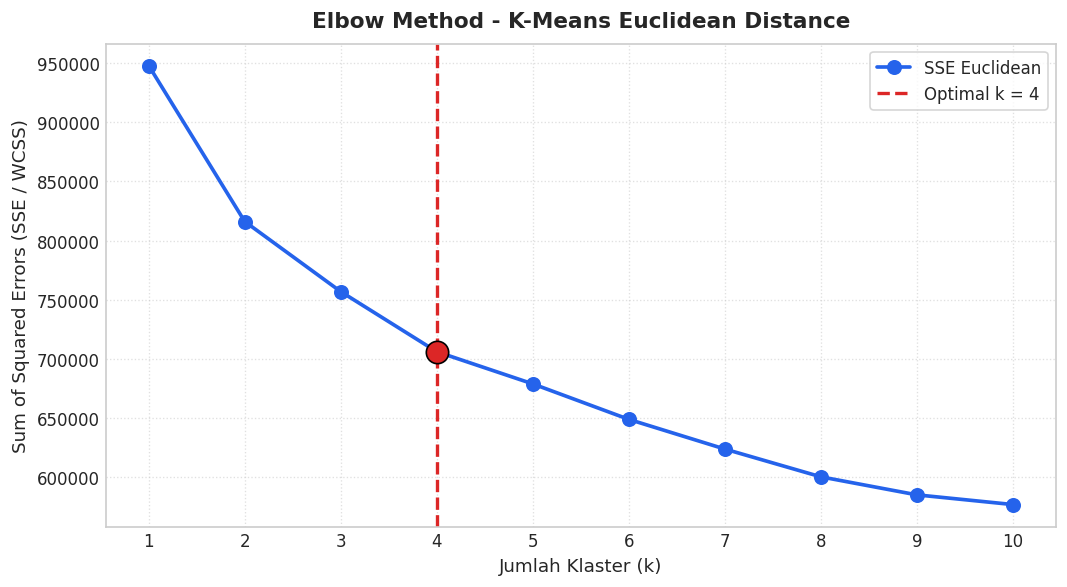

In [ ]:
k_range = list(range(1,11))
sse_euclidean = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=3, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    sse_euclidean.append(km.inertia_)
    print(f"  k = {k:<2} | SSE = {km.inertia_:,.1f}")

def find_elbow_point(k_vals, sses):
  p1 = np.array([k_vals[0], sses[0]])
  p2 = np.array([k_vals[-1], sses[-1]])
  line_vec = p2 - p1
  line_unit = line_vec / np.linalg.norm(line_vec)
  dists = [
      np.linalg.norm((np.array([k, s]) - p1) - np.dot(np.array([k, s]) - p1, line_unit) * line_unit)
      for k, s in zip(k_vals, sses)]
  return k_vals[int(np.argmax(dists))]

optimal_k = find_elbow_point(k_range, sse_euclidean)
print(f"[ELBOW] Jumlah klaster optimal terdeteksi: k = {optimal_k}")

plt.figure(figsize=(9, 5))
plt.plot(k_range, sse_euclidean, marker='o', markersize=8, linewidth=2.2, color='#2563EB', label='SSE Euclidean')  # kurva SSE
plt.axvline(x=optimal_k, color='#DC2626', linestyle='--', linewidth=2, label=f'Optimal k = {optimal_k}')
plt.scatter([optimal_k], [sse_euclidean[optimal_k - 1]], color='#DC2626', s=180, zorder=5, edgecolor='black')
plt.title('Elbow Method - K-Means Euclidean Distance', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Jumlah Klaster (k)', fontsize=11)              # label sumbu x
plt.ylabel('Sum of Squared Errors (SSE / WCSS)', fontsize=11)  # label sumbu y
plt.xticks(k_range)                                        # tampilkan semua angka k di sumbu x
plt.grid(True, linestyle=':', alpha=0.6)                   # tambah garis bantu tipis
plt.legend(frameon=True, facecolor='white')                # tampilkan legenda
plt.tight_layout()

elbow_path = os.path.join(OUTPUT_DIR, "elbow_euclidean.png")
plt.savefig(elbow_path, dpi=300)
print(f"[SIMPAN] Grafik Elbow disimpan ke: '{elbow_path}'")
plt.show()

## Kelas K-Means Euclidean

In [ ]:
class KMeansEuclidean:
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def _compute_distance(self, X, centroids):
        # Euclidean distance matrix: ||X - centroids||_2
        return pairwise_distances(X, centroids, metric='euclidean')

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples, _ = X.shape
        first_idx = rng.randint(n_samples)
        centroids = [X[first_idx]]

        for _ in range(1, self.n_clusters):
            cur_c = np.array(centroids)
            dists = self._compute_distance(X, cur_c)
            min_dists = np.min(dists, axis=1)
            sq_dists = min_dists ** 2
            sum_sq = np.sum(sq_dists)
            probs = np.ones(n_samples) / n_samples if sum_sq == 0 else sq_dists / sum_sq
            next_idx = rng.choice(n_samples, p=probs)
            centroids.append(X[next_idx])
        return np.array(centroids)

    def fit(self, X):
        start_time = time.perf_counter()
        self.centroids = self._init_centroids(X)

        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            # Assignment Step: Penugasan sampel ke centroid Euclidean terdekat
            dists = self._compute_distance(X, self.centroids)
            labels = np.argmin(dists, axis=1)

            # Update Step: Pembaruan posisi centroid menggunakan rata-rata aritmetika (mean)
            new_centroids = np.zeros_like(self.centroids)
            rng = np.random.RandomState(self.random_state)
            for k in range(self.n_clusters):
                cluster_pts = X[labels == k]
                if len(cluster_pts) == 0:
                    new_centroids[k] = X[rng.randint(len(X))]
                else:
                    new_centroids[k] = np.mean(cluster_pts, axis=0)

            # Pengecekan konvergensi pergeseran centroid
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.labels_ = labels

            if shift < self.tol:
                break

        # Komputasi Nilai Fungsi Objektif SSE: J = sum_{k=1}^K sum_{x in S_k} ||x - mu_k||_2^2
        final_dists = self._compute_distance(X, self.centroids)
        assigned_dists = final_dists[np.arange(len(X)), self.labels_]
        self.inertia_ = float(np.sum(assigned_dists ** 2))
        self.execution_time_ = float(time.perf_counter() - start_time)
        return self

print("[INFO] Kelas KMeansEuclidean berhasil diinisialisasi.")

[INFO] Kelas KMeansEuclidean berhasil diinisialisasi.


In [ ]:
# Membuat Model euclidean dan menjalankan klastering
model_euclidean = KMeansEuclidean(n_clusters=optimal_k, max_iter=300, tol=1e-4, random_state=RANDOM_STATE)
model_euclidean.fit(X_scaled)
labels = model_euclidean.labels_


sil_score = float(silhouette_score(X_scaled, labels, metric='euclidean', sample_size=10000, random_state=RANDOM_STATE))
db_score = float(davies_bouldin_score(X_scaled, labels)) # Score Davies-Bouldin (semakin kecil semakin bagus)
ch_score = float(calinski_harabasz_score(X_scaled, labels)) # Score Calinski-Harabasz (semakin besar semakin bagus)

eval_df = pd.DataFrame([{
    'Distance Metric': 'Euclidean Distance (L2)',
    'Optimal k': optimal_k,
    'Jumlah Data': X_scaled.shape[0],
    'Jumlah Fitur': X_scaled.shape[1],
    'Silhouette Score (↑)': round(sil_score, 4),
    'Davies–Bouldin Index (↓)': round(db_score, 4),
    'Calinski–Harabasz Index (↑)': round(ch_score, 2),
    'Execution Time (s) (↓)': round(model_euclidean.execution_time_, 5),
    'Objective Value (SSE) (↓)': round(model_euclidean.inertia_, 2)
}])

print("\n" + "="*80)
print("TABEL EVALUASI K-MEANS EUCLIDEAN")
print("="*80)
print(eval_df.to_string(index=False))
print("="*80)

df_clustered = df_features.copy()
df_clustered[LABEL] = y_label.values
df_clustered['Cluster_Euclidean'] = labels

profil = df_clustered.groupby('Cluster_Euclidean').mean().round(3)
profil['Jumlah Data'] = df_clustered['Cluster_Euclidean'].value_counts().sort_index()
profil['% Diabetes'] = (df_clustered.groupby('Cluster_Euclidean')[LABEL].apply(lambda s: (s == 1).mean() * 100)).round(2)

excel_path = os.path.join(OUTPUT_DIR, "evaluasi_kmeans_euclidean.xlsx")

with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    eval_df.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)  # sheet 1: ringkasan evaluasi
    profil.to_excel(writer, sheet_name='Profil_Klaster')   # sheet 2: profil rata-rata tiap klaster
print(f"[SIMPAN] Evaluasi & profil klaster disimpan ke: '{excel_path}'")

csv_path = os.path.join(OUTPUT_DIR, "data_terklaster.csv")  # lokasi CSV data terklaster
df_clustered.to_csv(csv_path, index=False)                 # simpan data lengkap + label klaster
print(f"[SIMPAN] Data terklaster disimpan ke: '{csv_path}'")


TABEL EVALUASI K-MEANS EUCLIDEAN
        Distance Metric  Optimal k  Jumlah Data  Jumlah Fitur  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)  Objective Value (SSE) (↓)
Euclidean Distance (L2)          4        63197            15                0.1068                    2.3585                      7218.13                 0.98014                  706021.99
[SIMPAN] Evaluasi & profil klaster disimpan ke: 'outputKmeans/evaluasi_kmeans_euclidean.xlsx'
[SIMPAN] Data terklaster disimpan ke: 'outputKmeans/data_terklaster.csv'


In [ ]:
# Profile tiap klaster
profil

,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Diabetes_binary,Jumlah Data,% Diabetes
Cluster_Euclidean,,,,,,,,,,,,,,,,,,
0,0.762,0.696,33.619,0.612,0.0,0.287,0.405,0.527,0.704,4.071,10.357,19.559,0.809,0.372,9.142,0.750,13352,74.96
1,0.812,0.719,30.498,0.602,1.0,0.456,0.561,0.594,0.713,3.659,6.531,12.253,0.578,0.464,9.960,0.744,4380,74.43
2,0.033,0.309,27.730,0.404,0.0,0.027,0.800,0.612,0.812,2.279,2.707,2.028,0.052,0.438,7.018,0.252,21979,25.22
3,0.962,0.643,30.609,0.484,0.0,0.162,0.732,0.603,0.777,2.770,1.617,2.100,0.139,0.519,9.579,0.617,23486,61.73


[SIMPAN] Grafik pemetaan klaster disimpan ke: 'outputKmeans/cluster_euclidean.png'


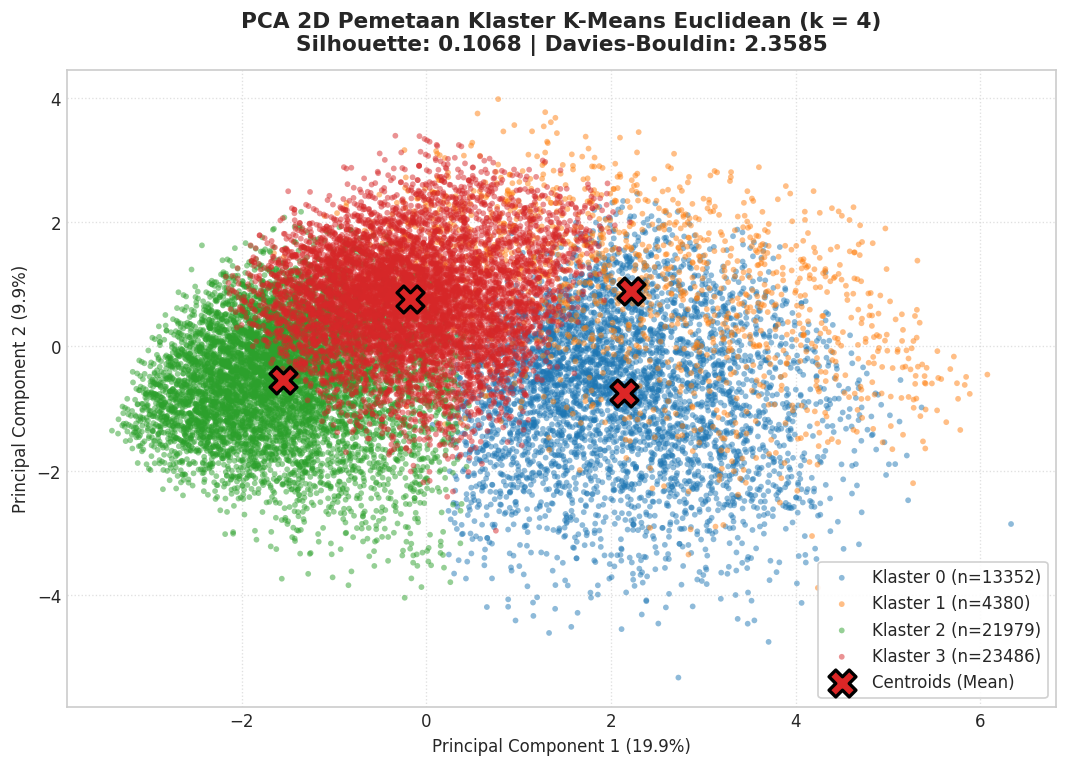

In [ ]:
# 8. VISUALISASI PCA 2D PEMETAAN KLASTER & CENTROIDS
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)                        # ubah data 20 dimensi jadi 2 dimensi
centroids_pca = pca.transform(model_euclidean.centroids)   # proyeksikan centroid ke ruang 2D yang sama

rng_plot = np.random.RandomState(RANDOM_STATE)             # generator acak untuk memilih sampel plot
n_plot = min(20000, len(X_pca))                            # jumlah titik yang digambar (maks 20.000)
idx_plot = rng_plot.choice(len(X_pca), size=n_plot, replace=False)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab10", optimal_k)

for k in range(optimal_k):
    mask = (labels[idx_plot] == k)
    plt.scatter(
        X_pca[idx_plot][mask, 0], X_pca[idx_plot][mask, 1],
        color=palette[k],
        label=f'Klaster {k} (n={np.sum(labels == k)})',
        alpha=0.5, s=12, edgecolors='none'
    )

plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    marker='X', s=260, c='#DC2626',
    edgecolor='black', linewidth=2,
    label='Centroids (Mean)', zorder=10
)

plt.title(f'PCA 2D Pemetaan Klaster K-Means Euclidean (k = {optimal_k})\n'
          f'Silhouette: {sil_score:.4f} | Davies-Bouldin: {db_score:.4f}',
          fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_euclidean.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SIMPAN] Grafik pemetaan klaster disimpan ke: '{cluster_path}'")
plt.show()

In [ ]:
loadings = pd.DataFrame(pca.components_.T, index=df_features.columns, columns=['PC1', 'PC2'])  # bobot tiap fitur di PC1 dan PC2
print("Fitur paling berpengaruh di PC1:")                   # judul
print(loadings['PC1'].abs().sort_values(ascending=False).head(6).round(3))  # 6 fitur terbesar di PC1
print("\nFitur paling berpengaruh di PC2:")                 # judul
print(loadings['PC2'].abs().sort_values(ascending=False).head(6).round(3))  # 6 fitur terbesar di PC2

Fitur paling berpengaruh di PC1:
GenHlth                 0.441
DiffWalk                0.408
PhysHlth                0.398
HighBP                  0.295
HeartDiseaseorAttack    0.264
PhysActivity            0.241
Name: PC1, dtype: float64

Fitur paling berpengaruh di PC2:
Age                     0.524
MentHlth                0.417
HighBP                  0.327
HeartDiseaseorAttack    0.308
HighChol                0.286
PhysHlth                0.256
Name: PC2, dtype: float64


In [ ]:
# ===== ARI & NMI vs label Diabetes_binary =====
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ALGO_NAME, METRIK_NAME = 'K-Means', 'Euclidean'

y_true = y_sample.values if 'y_sample' in globals() else y_label.values
lab = np.asarray(labels)
mk = lab != -1                                    # K-Means: semua True (tidak ada noise)

hasil_ext = pd.DataFrame([{
    'Algoritma': ALGO_NAME, 'Metrik': METRIK_NAME,
    'ARI (non-noise)':   round(adjusted_rand_score(y_true[mk], lab[mk]), 4),
    'NMI (non-noise)':   round(normalized_mutual_info_score(y_true[mk], lab[mk]), 4),
    'ARI (semua titik)': round(adjusted_rand_score(y_true, lab), 4),   # noise = 1 label (-1)
    'NMI (semua titik)': round(normalized_mutual_info_score(y_true, lab), 4),
}])
print(hasil_ext.to_string(index=False))

out = globals().get('OUTPUT_DIR', '.')
hasil_ext.to_excel(os.path.join(out, f'ari_nmi_{ALGO_NAME.lower()}_{METRIK_NAME.lower()}.xlsx'), index=False)

Algoritma    Metrik  ARI (non-noise)  NMI (non-noise)  ARI (semua titik)  NMI (semua titik)
  K-Means Euclidean           0.0972           0.0925             0.0972             0.0925


##